In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '3'
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt
import pyForwardFolding as pyFF
import jax
import nugget
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from math import inf
import pandas as pd
import torch
from nugget.samplers.sim_weights import event_arrays, generation_params, get_simulation_weights, get_ranged_simulation_weights

In [2]:
device = 'cuda:0'
signal_sampler = nugget.samplers.range_sampler.RangeSampler(
    device=device,
    E_min=1e2,
    E_max=1e6,
    energy_dist='log_uniform',
    injection_radius=1100,
    chunk_size=10000,
    seed=1,  # same events every time the notebook runs
)

num_events_total = int(1e5)
signal_events = signal_sampler.sample_events(num_events_total)
ev = event_arrays(signal_events)
# xsec = nugget.losses.effective_area.CrossSection()
# transmission = nugget.losses.effective_area.TransmissionProb()
# sim_weights = get_ranged_simulation_weights(
#     ev['energy'], ev['cos_zenith'],
#     xsec=xsec, transmission=transmission, batched=True, column_depth=ev['column_depth'],
#     **generation_params(signal_sampler),
# )
# sim_weights = sim_weights.cpu().numpy()

/ptmp/mpp/kristiantcho/nugget/nugget/samplers/range_sampler.py:52: UserWarning: torch.searchsorted(): boundary tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous boundary tensor if possible. This message will only appear once per program. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/BucketizationUtils.h:38.)
  idx = torch.searchsorted(self.r_out, r.contiguous())


In [4]:
for key in ev.keys():
    ev[key] = ev[key].cpu().numpy()

In [6]:
# save the event dictionary to a file
np.savez('signal_events.npz', **ev)


In [3]:
resolutions = torch.load('analysis_notebook_resolutions.pt')

In [56]:
resolutions.keys()

dict_keys(['initial hexagonal', 'optimised_nfold', 'optimised_dynamic', 'large'])

In [ ]:
event_energies = ev['energy'].cpu().numpy()
event_zenith = ev['zenith'].cpu().numpy()

energy_res = resolutions['optimised_nfold']['energy'].cpu().numpy()
zenith_res = resolutions['optimised_nfold']['zenith'].cpu().numpy()
# according to resolution sample a random energy and zenith centered around the true energy and zenith

#filter out events with a relative energy resolution greater than 1.0
valid_events = np.abs(energy_res / event_energies) < 1.0
event_energies = event_energies[valid_events]
event_zenith = event_zenith[valid_events]
energy_res = energy_res[valid_events]
zenith_res = zenith_res[valid_events]
sim_weights = sim_weights[valid_events]

reco_energy = np.random.normal(event_energies, energy_res)
reco_zenith = np.random.normal(event_zenith, zenith_res)
 
data = {"dataset": {
    "log10_reco_energy": jnp.log10(jnp.asarray(reco_energy)),
    "cos_reco_zenith": jnp.cos(jnp.asarray(reco_zenith)),
    "baseline_weight": jnp.asarray(sim_weights),
    "true_energy": jnp.asarray(event_energies),
    "true_zenith": jnp.asarray(event_zenith),
}}

In [ ]:
# n = int(5e6)
# event_energies = 10 ** np.random.uniform(2, 8, size=n)
# event_zenith   = np.arccos(np.random.uniform(-1, 1, size=n))

# reco_energy = 10 ** (np.log10(event_energies) + np.random.normal(0, 0.2, size=n))
# reco_zenith = np.arccos(
#     np.clip(np.cos(event_zenith) + np.random.normal(0, 0.05, size=n), -1, 1)
# )
# baseline_weights = event_energies * np.log(10) * 6 / n * 1e5

# data = {
#     "dataset": {
#         "log10_reco_energy": jnp.log10(jnp.asarray(reco_energy)),
#         "cos_reco_zenith":  jnp.cos(jnp.asarray(reco_zenith)),
#         "baseline_weight":  jnp.asarray(baseline_weights),
#         "true_energy":      jnp.asarray(event_energies),
#         "true_zenith":      jnp.asarray(event_zenith),
#     }
# }

/tmp/ipykernel_3527011/1440333448.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'Weighted Counts')

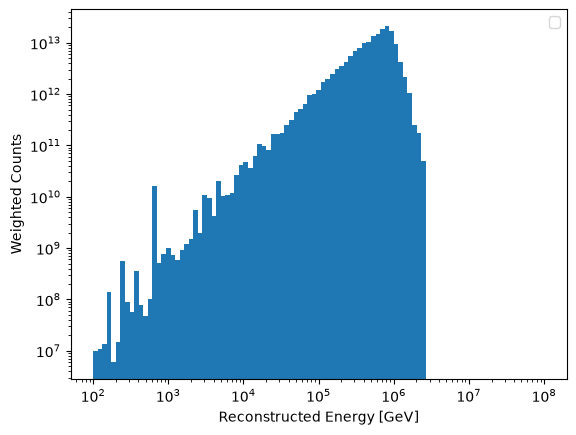

In [60]:
fig, ax = plt.subplots()
h = ax.hist(reco_energy, bins=np.logspace(2, 8, 100), weights=sim_weights)
plt.legend()
plt.loglog()
plt.xlabel("Reconstructed Energy [GeV]")
plt.ylabel("Weighted Counts")

In [61]:
config = '../other/pyFF_config_new.yaml'
ana = pyFF.config.analysis_from_config(config)
params, priors = pyFF.config.params_from_config(config)

In [62]:
obs, ssq = ana.evaluate(data,params)

In [63]:
cobs, cssq = ana.evaluate_per_component(data,params)

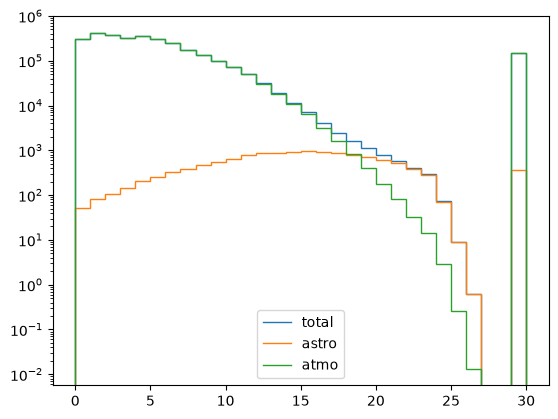

In [64]:
plt.stairs(obs["det1"].sum(axis=1),label="total")
plt.stairs(cobs["det1"]["astro"].sum(axis=1),label="astro")
plt.stairs(cobs["det1"]["atmo"].sum(axis=1),label="atmo")
plt.legend()
plt.yscale("log")

In [65]:
llh = pyFF.likelihood.PoissonLikelihood(ana,priors)
mini = pyFF.minimizer.ScipyMinimizer(llh)

In [66]:
mini.minimize(obs,data)

(  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   success: True
    status: 0
       fun: 2593.927269290534
         x: [ 2.000e+00  1.440e+00  1.000e+00]
       nit: 1
       jac: [ 1.110e-05  3.775e-06  1.727e-03]
      nfev: 6
      njev: 6
  hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64>,
 {'astro_index': np.float64(2.0000000000029527),
  'astro_norm': np.float64(1.4400000000009132),
  'atmo_norm': np.float64(1.0000000005643228)},
 np.float64(2593.927269290534))

In [67]:
norms = np.linspace(0,3,11)
llhs = []
for norm in norms:
    res = mini.minimize(obs,data,fixed_pars={"astro_norm":norm})
    llhs.append(res[2])
llhs = np.asarray(llhs)

In [68]:
dllhs = 2*(llhs-np.min(llhs))

Text(0, 0.5, '-2DeltaLLH')

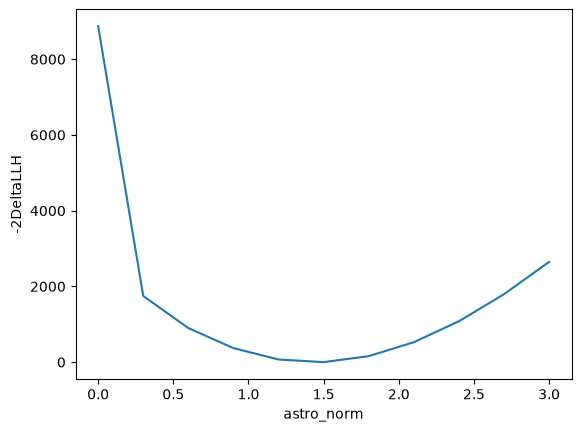

In [69]:
plt.plot(norms,dllhs)
plt.xlabel("astro_norm")
plt.ylabel("-2DeltaLLH")